In [1]:
%pip install qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
import numpy as np

# Create the quantum simulator
simulator = AerSimulator()

print("Libraries imported successfully!")

Libraries imported successfully!


PART A: CORRELATED OUTCOMES
Quantum gates before measurement: 2


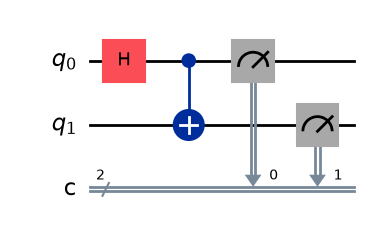

In [3]:
# Part A: Correlated outcomes
part_a = QuantumCircuit(2, 2)

# Create a Bell state
part_a.h(0)
part_a.cx(0, 1)

# Measure both qubits
part_a.measure([0, 1], [0, 1])

# Display the circuit
print("PART A: CORRELATED OUTCOMES")
print("Quantum gates before measurement: 2")
display(part_a.draw("mpl"))

In [4]:
compiled_a = transpile(part_a, simulator)

result_a = simulator.run(
    compiled_a,
    shots=100
).result()

counts_a = result_a.get_counts()

print("Part A Measurement Results:")
print(counts_a)
print("Total shots:", sum(counts_a.values()))

assert sum(counts_a.values()) == 100

Part A Measurement Results:
{'11': 48, '00': 52}
Total shots: 100


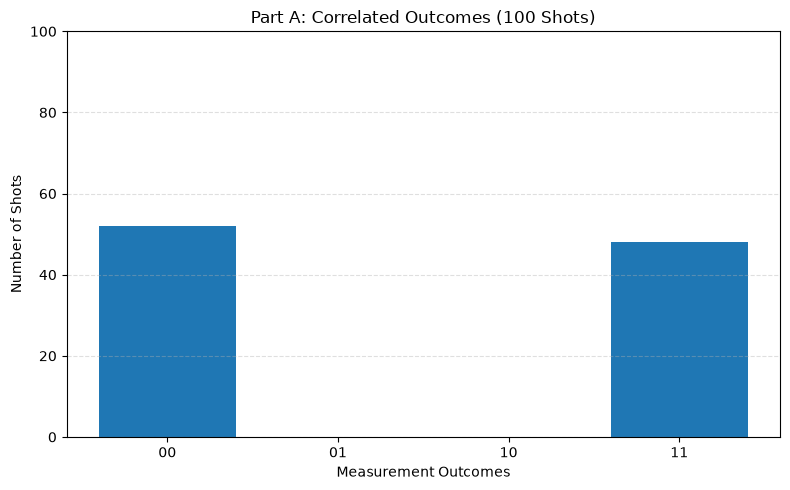

In [5]:
# Include all four outcomes, even if some have zero counts
outcomes = ["00", "01", "10", "11"]
values_a = [counts_a.get(outcome, 0) for outcome in outcomes]

plt.figure(figsize=(8, 5))
plt.bar(outcomes, values_a)

plt.xlabel("Measurement Outcomes")
plt.ylabel("Number of Shots")
plt.title("Part A: Correlated Outcomes (100 Shots)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

PART B: OPPOSITE OUTCOMES
Quantum gates before measurement: 3


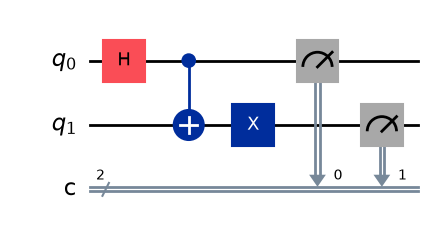

In [6]:
# Part B: Opposite outcomes
part_b = QuantumCircuit(2, 2)

# Start with the same Bell-state circuit
part_b.h(0)
part_b.cx(0, 1)

# Add one X gate to flip the second qubit
part_b.x(1)

# Measure both qubits
part_b.measure([0, 1], [0, 1])

# Display the circuit
print("PART B: OPPOSITE OUTCOMES")
print("Quantum gates before measurement: 3")
display(part_b.draw("mpl"))

In [7]:
compiled_b = transpile(part_b, simulator)

result_b = simulator.run(
    compiled_b,
    shots=100
).result()

counts_b = result_b.get_counts()

print("Part B Measurement Results:")
print(counts_b)
print("Total shots:", sum(counts_b.values()))

assert sum(counts_b.values()) == 100

Part B Measurement Results:
{'10': 42, '01': 58}
Total shots: 100


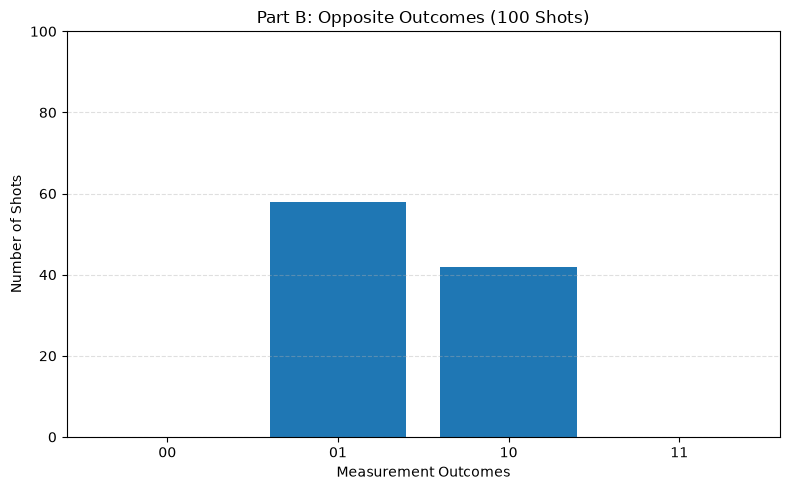

In [8]:
values_b = [counts_b.get(outcome, 0) for outcome in outcomes]

plt.figure(figsize=(8, 5))
plt.bar(outcomes, values_b)

plt.xlabel("Measurement Outcomes")
plt.ylabel("Number of Shots")
plt.title("Part B: Opposite Outcomes (100 Shots)")
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

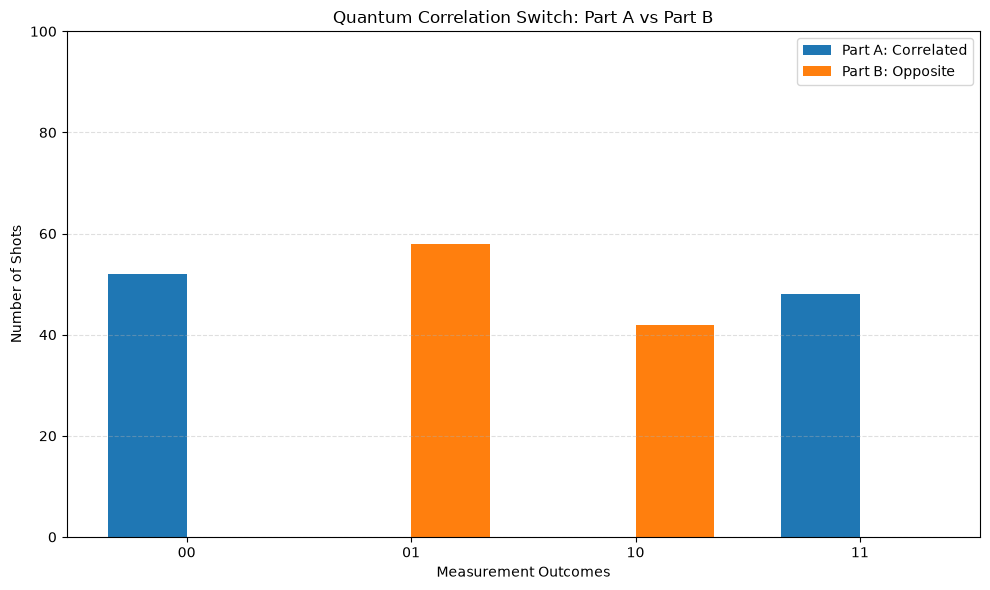

In [9]:
# Prepare comparison data
x = np.arange(len(outcomes))
width = 0.35

values_a = [counts_a.get(outcome, 0) for outcome in outcomes]
values_b = [counts_b.get(outcome, 0) for outcome in outcomes]

plt.figure(figsize=(10, 6))

plt.bar(
    x - width / 2,
    values_a,
    width,
    label="Part A: Correlated"
)

plt.bar(
    x + width / 2,
    values_b,
    width,
    label="Part B: Opposite"
)

plt.xlabel("Measurement Outcomes")
plt.ylabel("Number of Shots")
plt.title("Quantum Correlation Switch: Part A vs Part B")
plt.xticks(x, outcomes)
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [10]:
print("MEASUREMENT RESULTS COMPARISON")
print("-" * 45)
print(f"{'Outcome':<15}{'Part A':<15}{'Part B':<15}")
print("-" * 45)

for outcome in outcomes:
    a = counts_a.get(outcome, 0)
    b = counts_b.get(outcome, 0)
    print(f"{outcome:<15}{a:<15}{b:<15}")

print("-" * 45)
print("Part A total shots:", sum(counts_a.values()))
print("Part B total shots:", sum(counts_b.values()))

MEASUREMENT RESULTS COMPARISON
---------------------------------------------
Outcome        Part A         Part B         
---------------------------------------------
00             52             0              
01             0              58             
10             0              42             
11             48             0              
---------------------------------------------
Part A total shots: 100
Part B total shots: 100


In [11]:
# Check the required constraints
assert part_a.num_qubits == 2
assert part_b.num_qubits == 2

assert part_a.num_clbits == 2
assert part_b.num_clbits == 2

assert sum(counts_a.values()) == 100
assert sum(counts_b.values()) == 100

# Each circuit has two measurement instructions
# Remove them to count quantum gates
gates_a = sum(
    instruction.operation.name != "measure"
    and instruction.operation.name != "barrier"
    for instruction in part_a.data
)

gates_b = sum(
    instruction.operation.name != "measure"
    and instruction.operation.name != "barrier"
    for instruction in part_b.data
)

assert gates_a <= 4
assert gates_b <= 4

print("ALL REQUIREMENTS VERIFIED")
print("Part A: 2 qubits,", gates_a, "quantum gates, 100 shots")
print("Part B: 2 qubits,", gates_b, "quantum gates, 100 shots")
print("Both qubits measured in each circuit.")

ALL REQUIREMENTS VERIFIED
Part A: 2 qubits, 2 quantum gates, 100 shots
Part B: 2 qubits, 3 quantum gates, 100 shots
Both qubits measured in each circuit.
